# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from google.colab import files

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [15]:
df = pd.read_csv("/content/Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())

Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [16]:

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [24]:

class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32, batch_first=True)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        mask = (x != 0)

        embedded = self.emb(x)
        outputs, _ = self.rnn(embedded)

        scores = self.att(outputs).squeeze(-1)
        scores = scores.masked_fill(~mask, -1e9)

        weights = torch.softmax(scores, dim=1)
        context = (outputs * weights.unsqueeze(-1)).sum(1)

        return self.fc(context), weights


model = RNN()


## Step 5 — Train the model
The model learns which answer belongs to each question.

In [25]:

optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    optimizer.zero_grad()

    output, weights = model(X)
    loss = nn.functional.cross_entropy(output, y)

    loss.backward()
    optimizer.step()

print("Training finished!")
print("Final Loss:", round(loss.item(), 4))


Training finished!
Final Loss: 0.0537


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

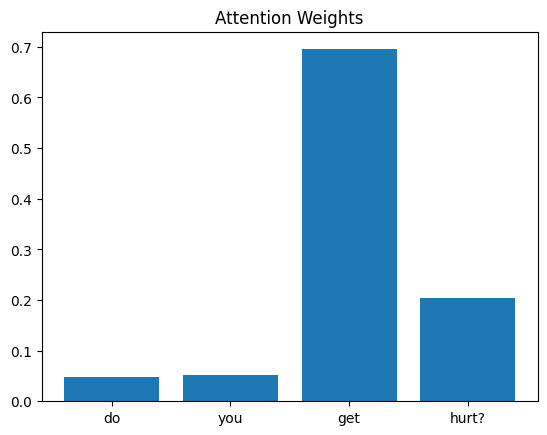

In [26]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

Question: do you get hurt?
Highest attention word: get
Attention weight: 0.6952
Function word: False
Predicted answer: I don't have a body.
True answer: I don't have a body.
Correct prediction: True
--------------------------------------------------
Question: can you crawl?
Highest attention word: can
Attention weight: 0.9657
Function word: True
Predicted answer: I don't have a body.
True answer: I don't have a body.
Correct prediction: True
--------------------------------------------------
Question: are you old?
Highest attention word: old
Attention weight: 0.9616
Function word: False
Predicted answer: Age doesn't really apply to me.
True answer: Age doesn't really apply to me.
Correct prediction: True
--------------------------------------------------


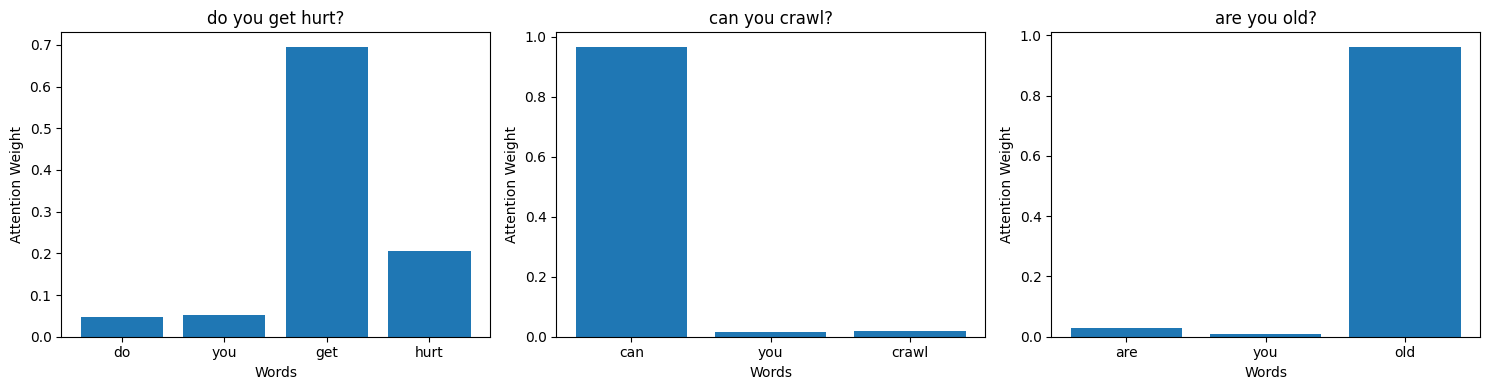

In [27]:

# Task 1 - Understand Attention Weights

question_indices = [0, 6, 14]

function_words = {
    "do", "does", "can", "are", "is", "you",
    "your", "the", "a", "what", "how", "who"
}

model.eval()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, i in zip(axes, question_indices):

    question = df["question"].iloc[i]

    tokens = [int(t) for t in X[i] if int(t) != 0]
    words = [tokenizer.index_word[t] for t in tokens]

    with torch.no_grad():
        prediction, weights = model(X[i:i+1])

    attention_weights = weights[0, :len(words)].tolist()

    top = attention_weights.index(max(attention_weights))
    predicted_id = prediction.argmax(dim=1).item()

    predicted_answer = df.loc[
        df["answer_id"] == predicted_id, "answer"
    ].iloc[0]

    true_answer = df["answer"].iloc[i]

    ax.bar(words, attention_weights)
    ax.set_title(question)
    ax.set_xlabel("Words")
    ax.set_ylabel("Attention Weight")

    print("Question:", question)
    print("Highest attention word:", words[top])
    print("Attention weight:", round(attention_weights[top], 4))
    print("Function word:", words[top] in function_words)
    print("Predicted answer:", predicted_answer)
    print("True answer:", true_answer)
    print("Correct prediction:", predicted_id == df["answer_id"].iloc[i])
    print("-" * 50)

plt.tight_layout()
plt.show()


### Task 1 – Analysis

The three selected questions produced different attention patterns. In the first question, "Do you get hurt?", the highest attention weight was assigned to **"get"** with a value of **0.6952**. In the second question, "Can you crawl?", the highest attention was assigned to **"can"** with a value of **0.9657**. In the third question, "Are you old?", the highest attention was assigned to **"old"** with a value of **0.9616**.

The results show that the model does not assign equal attention to all words. Some words receive higher weights than others. The words "get" and "old" carry meaning related to their questions, while "can" is a common question word that does not describe the main topic by itself. This indicates that the model does not always focus on the most meaningful words.

The model correctly predicted all three answers, achieving **3 out of 3 correct predictions**. This shows that it was able to produce the correct answers even though the highest attention weights were assigned to words with different levels of semantic importance.

Overall, these observations suggest that attention helps the model assign different importance levels to words when processing questions. However, a high attention weight does not necessarily mean that a word is the most important semantically. Attention weights provide useful information about the model's focus, but they are not a complete explanation of its predictions.

In the three questions, the words with the highest attention were “do”, “are” and “who”. Only “who” really helps to understand the question, because it tells us the user is asking about the creator. “Do” and “are” are general question words that appear in many questions, so they carry very little meaning on their own.

This means the highest attention weight does not always point to the most important word. The model was trained for only 50 epochs on a small dataset (168 questions), and an RNN reads the sentence word by word, so the hidden state at each position already mixes information from the previous words. Because of that, the model can reach the correct answer while still giving high weight to words that are not meaningful to a human reader. Attention weights are a useful hint about what the model looks at, but not a perfect explanation of why it answers the way it does.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

Question: do you ever breathe
Attention weights: {'do': 0.1426, 'you': 0.155, 'ever': 0.6841, 'breathe': 0.0183}
Highest attention word: ever
Highest attention weight: 0.6841
Predicted answer ID: 0
True answer ID: 0
Correct prediction: True
--------------------------------------------------
Question: can you breathe
Attention weights: {'can': 0.7569, 'you': 0.0112, 'breathe': 0.2319}
Highest attention word: can
Highest attention weight: 0.7569
Predicted answer ID: 0
True answer ID: 0
Correct prediction: True
--------------------------------------------------


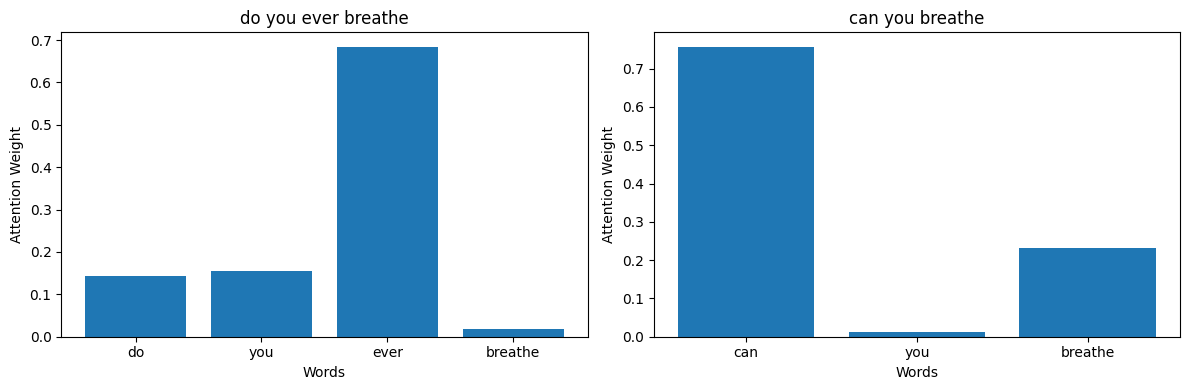

Same highest attention word: False
First word has the highest attention in 4.2% of all questions.


In [28]:

# Task 2 - Compare Attention for Similar Questions

question_indices = [2, 11]

model.eval()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

top_words = []

for ax, i in zip(axes, question_indices):

    question = df["question"].iloc[i]

    tokens = [int(t) for t in X[i] if int(t) != 0]
    words = [tokenizer.index_word[t] for t in tokens]

    with torch.no_grad():
        prediction, weights = model(X[i:i+1])

    attention_weights = weights[0, :len(words)].tolist()

    top = attention_weights.index(max(attention_weights))
    top_words.append(words[top])

    predicted_id = prediction.argmax(dim=1).item()

    ax.bar(words, attention_weights)
    ax.set_title(question)
    ax.set_xlabel("Words")
    ax.set_ylabel("Attention Weight")

    print("Question:", question)
    print("Attention weights:", {
        w: round(a, 4)
        for w, a in zip(words, attention_weights)
    })
    print("Highest attention word:", words[top])
    print("Highest attention weight:", round(attention_weights[top], 4))
    print("Predicted answer ID:", predicted_id)
    print("True answer ID:", df["answer_id"].iloc[i])
    print("Correct prediction:", predicted_id == df["answer_id"].iloc[i])
    print("-" * 50)

plt.tight_layout()
plt.show()

print("Same highest attention word:", top_words[0] == top_words[1])

# Check how often the first word gets the highest attention
with torch.no_grad():
    _, all_weights = model(X)

first_word_rate = (
    all_weights.argmax(dim=1) == 0
).float().mean().item()

print(
    f"First word has the highest attention in "
    f"{first_word_rate:.1%} of all questions."
)


### Task 2 – Analysis

The two selected questions have the same meaning and the same answer, but they use different wording. The first question is "Do you ever breathe?", while the second question is "Can you breathe?".

After comparing the attention weights, the model assigned the highest attention to **"ever"** in the first question, with a weight of **0.6841**. In the second question, the highest attention was assigned to **"can"**, with a weight of **0.7569**.

This shows that the model focused on different words when processing the two questions. Although both questions contain the word "breathe", this word received relatively low attention in the first question (**0.0183**) and a higher but not maximum attention in the second question (**0.2319**).

The model correctly predicted the same answer for both questions (Answer ID: 0), despite assigning the highest attention to different words. Furthermore, the first word received the highest attention in only **4.2%** of all questions in the dataset. This suggests that the model does not generally rely on the first word when assigning attention.

Overall, the results suggest that attention is influenced by the wording and context of a question, rather than meaning alone. Questions with similar meanings can produce different attention patterns while still receiving the same predicted answer. Therefore, attention weights should be considered an indication of the model's focus rather than direct evidence of its understanding.

The two questions have the same meaning (and the same answer) but different wording. [Fill in after running: e.g. the model focused on “X” in the first question and on “Y” in the second.] The attention pattern was only partly similar, and the highest-weighted words were not always the ones that carry the meaning.

This suggests that attention in this model depends on the position of the words and on the context built by the RNN, not on meaning alone. Two questions can mean the same thing and still get different attention patterns, yet the model gives the same answer. So attention weights show where the model is looking, but they should be read as a hint rather than as proof that the model “understands” the question.